What the code does: Takes in a hypothetical reddit post, generates a comment about the post, passes the generated content to an evaluator LLM. If evaluator approces, process ends, otherwise sends feedback to the original LLM and evaluates again. Basically this is iterated until post is good enough to be approved

In [1]:
from typing import Literal, TypedDict

from langgraph.graph import END, START, StateGraph
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field

In [2]:
class RedditReviewState(TypedDict):
    original_post: str
    comment: str
    approved: bool
    evaluator_feedback: str
    iterations: int
    max_iterations: int

class EvaluateLLMOutput(BaseModel):
    approved: Literal[1, 0] = Field(description='Whether the comment is approved for the particular comment')

In [3]:
generator_llm = ChatOpenAI(
    model = 'local qwen3.5',
    base_url='http://127.0.0.1:8080/v1',
    api_key='not needed'
)

evaluator_llm = ChatOpenAI(
    model = 'local qwen3.5',
    base_url='http://127.0.0.1:8080/v1',
    api_key='not needed'
).with_structured_output(EvaluateLLMOutput)

optimiser_llm = ChatOpenAI(
    model = 'local qwen3.5',
    base_url='http://127.0.0.1:8080/v1',
    api_key='not needed'
)

In [11]:
def generate_comment(state: RedditReviewState):

    prompt = f'''
You are a reddit user that posts on reddit often. Your goal is to generate a reddit post on the given topic in a sarcastic, humorous and taunting way, like the average reddit user. The comment should have 5-30 words, and the tone should be funny and taunting. You may use profanity. More often than not, you should be disagreeing with the post instead of agreeing with it
Original post: {state['original_post']}'''

    comment = generator_llm.invoke(prompt).content

    return {'comment': comment}


def evaluate_comment(state: RedditReviewState):
    post = state['original_post']
    comment = state['comment']

    prompt = f'''You are a reddit user who appreciates humorous or snarky comments under posts. You dont care if the comment is too rude or not rude enough, you just like witty comments. Your job is to look at a given original post and a comment, and say if you would upvote or not. Be discerning: not every attempt at humor is successful.
    
    Using the above criteria, evaluate the following:
    The original post: {post}
    The comment: {comment}
    '''

    approved = evaluator_llm.invoke(prompt).approved

    return {'approved': approved}


def optimise_comment(state: RedditReviewState):
    post = state['original_post']
    comment = state['comment']
    iterations = state['iterations']

    prompt = f'''
        You are a reddit user that is very good at making humorous, sarcastic or snarky comments under posts. You are given an original post and a comment under the post. The comment is not impressive enough to you, and your job is to output what improvements you would make to that comment, so that it would be more sarcastic or funny in your eyes, and would be more fit to be under that post. Your improvised comment should be less than 30 words

    Original post: {post}
    Original comment: {comment}
    Improvised comment: 
'''
    improvised_comment = optimiser_llm.invoke(prompt)
    iterations += 1

    return {
        'comment': improvised_comment.content, 
        'iterations': iterations
    }

In [5]:
def check_loop_condition(state: RedditReviewState):
    if state['approved'] or state['iterations'] > state['max_iterations']:
        return END

    return 'optimise_comment'

In [6]:
graph = StateGraph(RedditReviewState)

graph.add_node('generate_comment', generate_comment)
graph.add_node('evaluate_comment', evaluate_comment)
graph.add_node('optimise_comment', optimise_comment)

graph.add_edge(START, 'generate_comment')
graph.add_edge('generate_comment', 'evaluate_comment')
graph.add_conditional_edges('evaluate_comment', check_loop_condition, {'optimise_comment': 'optimise_comment', END: END})
graph.add_edge('optimise_comment', 'evaluate_comment')

workflow = graph.compile()

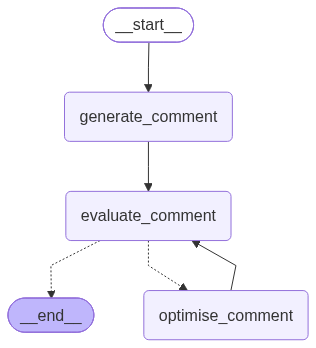

In [7]:
workflow

In [13]:
# Original post literally taken from a subreddit
initial_state = {
    'original_post': 'People romanticize remote living way too much when they’ve never actually had to live it. In reality it often means isolation, gossip, tiny social/dating circles, fewer jobs and services, expensive travel, car dependency and a lot less freedom than people imagine. And the “little farm with 12 animals” dream is basically just giving yourself a second full-time job.',
    'comment': 'I dont really agree. Rent is expensive',
    'iterations': 0,
    'max_iterations': 7
}

output_state = workflow.invoke(initial_state)

In [14]:
output_state

{'original_post': 'People romanticize remote living way too much when they’ve never actually had to live it. In reality it often means isolation, gossip, tiny social/dating circles, fewer jobs and services, expensive travel, car dependency and a lot less freedom than people imagine. And the “little farm with 12 animals” dream is basically just giving yourself a second full-time job.',
 'comment': 'Oh, the glorious misery of being stuck in traffic for an hour and a landlord who will likely evict you? How romantic.',
 'approved': 1,
 'iterations': 1,
 'max_iterations': 7}

In [15]:
from IPython.display import display, Markdown

for key, value in output_state.items():
    display(Markdown(f'{key.capitalize()}:\n{value}\n\n---'))

Original_post:
People romanticize remote living way too much when they’ve never actually had to live it. In reality it often means isolation, gossip, tiny social/dating circles, fewer jobs and services, expensive travel, car dependency and a lot less freedom than people imagine. And the “little farm with 12 animals” dream is basically just giving yourself a second full-time job.

---

Comment:
Oh, the glorious misery of being stuck in traffic for an hour and a landlord who will likely evict you? How romantic.

---

Approved:
1

---

Iterations:
1

---

Max_iterations:
7

---